# Adversarial Search: Playing Connect 4

Student Name: Ngô Đông Ất

Student ID: 3123410014

Course: Trí tuệ Nhân tạo Nâng cao (Advanced AI) — GVHD: TS. Đỗ Như Tài


## Learning Outcomes

* Implement adversarial search algorithms for strategic game play.
* Analyze and optimize search in complex game spaces.
* Design effective heuristic evaluation functions.
* Compare performance across different agent strategies.
* Evaluate algorithmic trade-offs between decision quality and efficiency.

## Instructions

Total Points: Undergraduates 100, graduate students 110

Complete this notebook and submit it. The notebook needs to be a complete project report with your implementation, documentation including a short discussion of how your implementation works and your design choices, and experimental results (e.g., tables and charts with simulation results) with a short discussion of what they mean. Use the provided notebook cells and insert additional code and markdown cells as needed. Submit the completely rendered notebook as a HTML file. 


## Introduction

You will implement different versions of agents that play Connect 4:

> "Connect 4 is a two-player connection board game, in which the players choose a color and then take turns dropping colored discs into a seven-column, six-row vertically suspended grid. The pieces fall straight down, occupying the lowest available space within the column. The objective of the game is to be the first to form a horizontal, vertical, or diagonal line of four of one's own discs." (see [Connect Four on Wikipedia](https://en.wikipedia.org/wiki/Connect_Four))

Note that [Connect-4 has been solved](https://en.wikipedia.org/wiki/Connect_Four#Mathematical_solution)
in 1988. A connect-4 solver with a discussion of how to solve different parts of the problem can be found here: https://connect4.gamesolver.org/en/

In [1]:
# change directory to Google Drive for Google Colab
try:
    from google.colab import drive
    import os

    drive.mount('/content/drive')
    os.chdir('/content/drive/My Drive/Colab Notebooks/')
    print("Your working directory is now Google Drive: My Drive > Colab Notebooks")
except ImportError:
    pass

## Task 1: Defining the Search Problem [10 point]

Define the components of the search problem:

* Initial state
* Actions
* Transition model (result function)
* Goal state (terminal state and utility)

Describe each component and then implement it as a function that can be used by search algorithms.

In [2]:
# Task 1: Định nghĩa bài toán tìm kiếm Connect 4
import numpy as np
import math, time, cProfile, pstats, io
import pandas as pd
import matplotlib.pyplot as plt

def empty_board(shape=(6, 7)):
    """Trạng thái ban đầu S0: lưới rỗng kích thước shape (mặc định 6x7) chứa toàn số 0."""
    return np.zeros(shape, dtype=np.int8)

print('Initial state S0 (6x7):')
print(empty_board())
print('Các thành phần: Initial state (6x7 zeros), Actions (các cột có ô trên cùng == 0), '
      'Result (thả quân rơi xuống hàng trống thấp nhất), Terminal (có 4 quân thẳng hàng hoặc đầy bàn), '
      'Utility (+1 Đỏ thắng, -1 Vàng thắng, 0 Hòa).')


Initial state S0 (6x7):
[[0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]]
Các thành phần: Initial state (6x7 zeros), Actions (các cột có ô trên cùng == 0), Result (thả quân rơi xuống hàng trống thấp nhất), Terminal (có 4 quân thẳng hàng hoặc đầy bàn), Utility (+1 Đỏ thắng, -1 Vàng thắng, 0 Hòa).


How big is the state space? Give an estimate and explain it.

### Ước tính kích thước không gian trạng thái (State Space Size):
1. **Cận trên thô (Naive Upper Bound):** Mỗi ô trong $42$ ô có thể mang $3$ giá trị ($0, 1, -1$) $\implies 3^{42} \approx 1.094 \times 10^{20}$ cấu hình.
2. **Ràng buộc vật lý trọng lực:** Do quân cờ rơi xuống đáy, mỗi cột chiều cao $h \in \{0..6\}$ có $2^h$ cách điền quân, nên một cột có $\sum_{h=0}^6 2^h = 127$ trạng thái hợp lệ. Cận theo trọng lực là $127^7 \approx 5.37 \times 10^{14}$.
3. **Số trạng thái hợp lệ chính xác (John Tromp, 1988):** Sau khi loại trừ các bàn cờ không đạt tới được hoặc tiếp tục sau khi đã thắng, không gian trạng thái chính xác của Connect 4 ($6 \times 7$) là **$4,531,985,219,092 \approx 4.53 \times 10^{12}$** trạng thái.

How big is the game tree that minimax search will go through? Give an estimate and explain it.

### Ước tính kích thước cây trò chơi (Game Tree Size):
1. **Cận trên lý thuyết:** Hệ số phân nhánh tối đa $b = 7$, độ sâu tối đa $m = 42$ $\implies 7^{42} \approx 3.12 \times 10^{35}$ nút lá.
2. **Ước tính thực tế:** Trung bình một ván kết thúc sau ~36 nước với hệ số phân nhánh trung bình $b \approx 4$, nên kích thước cây vào khoảng $4^{36} \approx 4.7 \times 10^{21}$ nút.
3. **Kết luận:** Việc duyệt toàn bộ cây bằng Minimax thuần túy trên bàn chuẩn $6 \times 7$ hoàn toàn **bất khả thi**, cần dùng Heuristic Cutoff và/hoặc Monte Carlo Search.

## Task 2: Game Environment and Random Agent [25 point]

Use a numpy character array as the board.

In [3]:
import numpy as np

def empty_board(shape=(6, 7)):
    return np.full(shape=shape, fill_value=0)

print(empty_board())

[[0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]]


The standard board is $6 \times 7$ but you can use smaller boards to test your code. Instead of colors (red and yellow), I use 1 and -1 to represent the players. Make sure that your agent functions all have the from: `agent_type(board, player = 1)`, where board is the current board position (in the format above) and player is the player whose next move it is and who the agent should play (as 1 and -1).

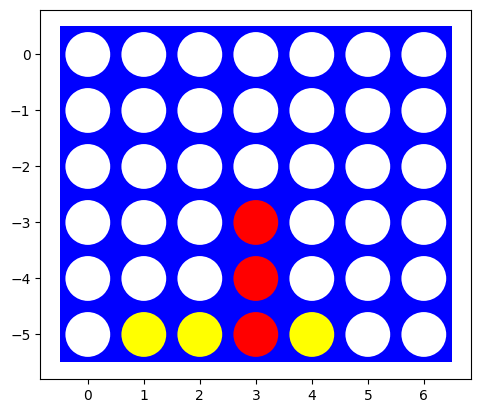

In [4]:
# Visualization code by Randolph Rankin

import matplotlib.pyplot as plt

def visualize(board):
    plt.axes()
    rectangle=plt.Rectangle((-0.5,len(board)*-1+0.5),len(board[0]),len(board),fc='blue')
    circles=[]
    for i,row in enumerate(board):
        for j,val in enumerate(row):
            color='white' if val==0 else 'red' if val==1 else 'yellow'
            circles.append(plt.Circle((j,i*-1),0.4,fc=color))

    plt.gca().add_patch(rectangle)
    for circle in circles:
        plt.gca().add_patch(circle)

    plt.axis('scaled')
    plt.show()
    
board = [[0, 0, 0, 0, 0, 0, 0],
         [0, 0, 0, 0, 0, 0, 0],
         [0, 0, 0, 0, 0, 0, 0],
         [0, 0, 0, 1, 0, 0, 0],
         [0, 0, 0, 1, 0, 0, 0],
         [0,-1,-1, 1,-1, 0, 0]]
visualize(board)

Implement helper functions for:

* A check for available actions in each state `actions(state)`.
* The transition model `result(state, player, action)`.
* Check for terminal states `terminal(state)`.
* The utility function `utility(state, player)`.

The player argument is used so your agent can play red or yellow.
Make sure that all these functions work with boards of different sizes (number of columns and rows).
You can follow the [tic-tac-toe example from class.](tictactoe_definitions.ipynb)

In [5]:
def actions(state):
    """Trả về danh sách các chỉ số cột hợp lệ (hàng trên cùng còn trống)."""
    return [c for c in range(state.shape[1]) if state[0, c] == 0]

def drop_piece(state, col, player):
    """Thả quân vào cột col, trả về (new_board, row_placed)."""
    new_b = state.copy()
    for r in range(state.shape[0] - 1, -1, -1):
        if new_b[r, col] == 0:
            new_b[r, col] = player
            return new_b, r
    raise ValueError(f'Cột {col} đã đầy!')

def result(state, player, action):
    """Transition model: trả về trạng thái mới sau khi player đi cột action."""
    nb, _ = drop_piece(state, action, player)
    return nb

def check_win_fast(board, r, c, player, k=4):
    """Kiểm tra nhanh chiến thắng k quân liên tiếp đi qua ô (r, c)."""
    rows, cols = board.shape
    # Ngang
    consec = 0
    for j in range(max(0, c - k + 1), min(cols - 1, c + k - 1) + 1):
        consec = consec + 1 if board[r, j] == player else 0
        if consec >= k: return True
    # Dọc
    if r + k <= rows and all(board[r + i, c] == player for i in range(k)):
        return True
    # Chéo \\
    consec = 0
    for step in range(max(-min(r, c), -k + 1), min(min(rows - 1 - r, cols - 1 - c), k - 1) + 1):
        consec = consec + 1 if board[r + step, c + step] == player else 0
        if consec >= k: return True
    # Chéo /
    consec = 0
    for step in range(max(-min(rows - 1 - r, c), -k + 1), min(min(r, cols - 1 - c), k - 1) + 1):
        consec = consec + 1 if board[r - step, c + step] == player else 0
        if consec >= k: return True
    return False

def check_board_winner(board, k=4):
    rows, cols = board.shape
    for r in range(rows):
        for c in range(cols):
            p = board[r, c]
            if p != 0 and check_win_fast(board, r, c, p, k):
                return int(p)
    return 0

def terminal(state, k=4):
    if check_board_winner(state, k) != 0: return True
    return len(actions(state)) == 0

def utility(state, player=1, k=4):
    w = check_board_winner(state, k)
    if w == player: return 1.0
    if w == -player: return -1.0
    if len(actions(state)) == 0: return 0.0
    return None

b_chk = empty_board()
b_chk = result(result(result(result(b_chk, 1, 0), 1, 1), 1, 2), 1, 3)
print('Kiểm tra win ngang:', terminal(b_chk), 'Utility for 1:', utility(b_chk, 1))


Kiểm tra win ngang: True Utility for 1: 1.0


Implement an agent that plays randomly. Make sure the agent function receives as the percept the board and returns a valid action. Use an agent function definition with the following signature (arguments):

`def random_player(board, player = 1): ...`

The argument `player` is used for agents that do not store what color they are playing. The value passed on by the environment should be 1 ot -1 for player red and yellow, respectively.  See [Experiments section for tic-tac-toe](tictactoe_and_or_tree_search.ipynb#Experiments) for an example.

In [6]:
def random_player(board, player=1):
    acts = actions(board)
    if not acts: return None
    return int(np.random.choice(acts))

def play_c4(p1, p2, shape=(6, 7), k=4, N=100):
    res = {1: 0, -1: 0, 0: 0}
    for _ in range(N):
        b = empty_board(shape)
        curr = 1
        won = False
        for _ in range(shape[0] * shape[1]):
            acts = actions(b)
            if not acts: break
            col = p1(b, 1) if curr == 1 else p2(b, -1)
            b, r = drop_piece(b, col, curr)
            if check_win_fast(b, r, col, curr, k):
                res[curr] += 1; won = True; break
            curr = -curr
        if not won: res[0] += 1
    return res

print('Random player và hàm play_c4 đã sẵn sàng!')


Random player và hàm play_c4 đã sẵn sàng!


Let two random agents play against each other 1000 times. Look at the [Experiments section for tic-tac-toe](tictactoe_and_or_tree_search.ipynb#Experiments) to see how the environment uses the agent functions to play against each other.

How often does each player win? Is the result expected?

1.000 ván Random vs Random (0.256s): {1: 532, -1: 468, 0: 0}
Đỏ (+1, đi trước): 53.2% | Vàng (-1, đi sau): 46.8% | Hòa: 0.0%


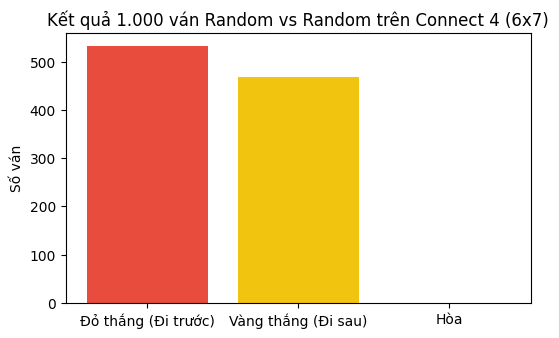

In [7]:
np.random.seed(42)
t0 = time.time()
res_rnd_1000 = play_c4(random_player, random_player, shape=(6, 7), k=4, N=1000)
dt_rnd = time.time() - t0
print(f'1.000 ván Random vs Random ({dt_rnd:.3f}s): {res_rnd_1000}')
print(f'Đỏ (+1, đi trước): {res_rnd_1000[1]/10:.1f}% | Vàng (-1, đi sau): {res_rnd_1000[-1]/10:.1f}% | Hòa: {res_rnd_1000[0]/10:.1f}%')

plt.figure(figsize=(6, 3.5))
plt.bar(['Đỏ thắng (Đi trước)', 'Vàng thắng (Đi sau)', 'Hòa'], [res_rnd_1000[1], res_rnd_1000[-1], res_rnd_1000[0]], color=['#e74c3c', '#f1c40f', '#95a5a6'])
plt.title('Kết quả 1.000 ván Random vs Random trên Connect 4 (6x7)')
plt.ylabel('Số ván')
plt.show()


## Task 3: Minimax Search with Alpha-Beta Pruning

### Implement the Search [10 points] 

Implement minimax search starting from a given board for specifying the player.

__Important Notes:__ 
* You can reuse code from the [tic-tac-toe examples](.).
* Make sure that all your agent functions have a signature consistent with the random agent above and that it [uses a class to store state information.](store_agent_state_information.ipynb)
This is essential to be able play against agents from other students later.
* The game tree for a $6 \times 7$ board is huge and optimal algorithms need to visit each or a large percentage of all nodes in the tree. You can experiment with smaller boards like a $4 \times 4$ board first.

In [8]:
class Connect4AlphaBetaAgent:
    """Lưu trạng thái thống kê số nút duyệt và thời gian cho mỗi lượt đi."""
    def __init__(self, k=4, order_fn=None):
        self.k = k
        self.order_fn = order_fn or actions
        self.nodes = 0

    def search(self, board, player=1):
        self.nodes = 0
        val, mv = self._max(board, player, player, -math.inf, +math.inf)
        return {'move': mv, 'value': val, 'nodes': self.nodes}

    def _max(self, b, p, root, alpha, beta):
        self.nodes += 1
        acts = self.order_fn(b)
        if not acts: return 0.0, None
        best_v, best_m = -math.inf, None
        for a in acts:
            nb, r = drop_piece(b, a, p)
            if check_win_fast(nb, r, a, p, self.k):
                return (1.0 if p == root else -1.0), a
            v, _ = self._min(nb, -p, root, alpha, beta)
            if v > best_v:
                best_v, best_m = v, a
                alpha = max(alpha, best_v)
            if best_v >= beta: return best_v, best_m
        return best_v, best_m

    def _min(self, b, p, root, alpha, beta):
        self.nodes += 1
        acts = self.order_fn(b)
        if not acts: return 0.0, None
        best_v, best_m = +math.inf, None
        for a in acts:
            nb, r = drop_piece(b, a, p)
            if check_win_fast(nb, r, a, p, self.k):
                return (1.0 if p == root else -1.0), a
            v, _ = self._max(nb, -p, root, alpha, beta)
            if v < best_v:
                best_v, best_m = v, a
                beta = min(beta, best_v)
            if best_v <= alpha: return best_v, best_m
        return best_v, best_m

    def __call__(self, board, player=1):
        return self.search(board, player)['move']

def minimax_raw(board, player=1, k=4):
    cnt = [0]
    def _mm(b, p, root):
        cnt[0] += 1
        acts = actions(b)
        if not acts: return 0.0, None
        bv, bm = (-math.inf if p == root else +math.inf), None
        for a in acts:
            nb, r = drop_piece(b, a, p)
            if check_win_fast(nb, r, a, p, k): return (1.0 if p == root else -1.0), a
            v, _ = _mm(nb, -p, root)
            if (p == root and v > bv) or (p != root and v < bv): bv, bm = v, a
        return bv, bm
    v, m = _mm(board, player, player)
    return {'move': m, 'value': v, 'nodes': cnt[0]}

print('Connect4AlphaBetaAgent và minimax_raw đã sẵn sàng!')


Connect4AlphaBetaAgent và minimax_raw đã sẵn sàng!


Experiment with some manually created boards (at least 5) to check if the agent spots winning opportunities.

4x4 Thắng ngay (kỳ vọng cột 3): {'move': 3, 'value': 1.0, 'nodes': 1053}
4x4 Chặn ngay  (kỳ vọng cột 0): {'move': 0, 'value': 0.0, 'nodes': 2308}
1. Thắng ngang: thắng ngay=[3], chặn đối thủ=[]
2. Thắng dọc: thắng ngay=[2], chặn đối thủ=[3]
3. Thắng chéo \: thắng ngay=[3], chặn đối thủ=[4]
4. Thắng chéo /: thắng ngay=[0], chặn đối thủ=[]
5. Chặn 3 quân: thắng ngay=[], chặn đối thủ=[0, 4]


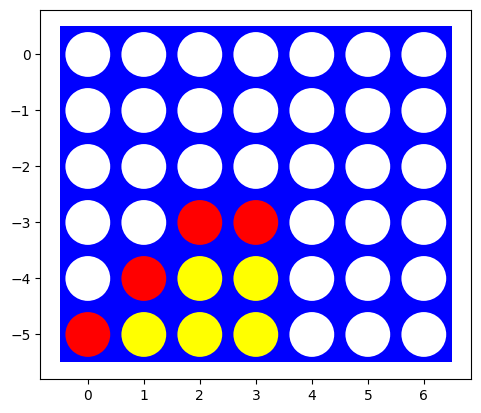

In [9]:
# Tạo 5 thế cờ kiểm thử (đã đi nhiều quân để Alpha-Beta đầy đủ xử lý nhanh trên 6x7 hoặc kiểm thử k=4)
b_t1 = empty_board((6, 7)); b_t1[5,0]=1; b_t1[5,1]=1; b_t1[5,2]=1; b_t1[4,0]=-1; b_t1[4,1]=-1; b_t1[4,2]=-1
b_t2 = empty_board((6, 7)); b_t2[5,2]=1; b_t2[4,2]=1; b_t2[3,2]=1; b_t2[5,3]=-1; b_t2[4,3]=-1; b_t2[3,3]=-1
b_t3 = empty_board((6, 7)); b_t3[5,0]=1; b_t3[5,1]=-1; b_t3[4,1]=1; b_t3[5,2]=-1; b_t3[4,2]=-1; b_t3[3,2]=1; b_t3[5,3]=-1; b_t3[4,3]=-1; b_t3[3,3]=1
b_t4 = empty_board((6, 7)); b_t4[5,3]=1; b_t4[5,2]=-1; b_t4[4,2]=1; b_t4[5,1]=-1; b_t4[4,1]=-1; b_t4[3,1]=1; b_t4[5,0]=-1; b_t4[4,0]=-1; b_t4[3,0]=1
b_t5 = empty_board((6, 7)); b_t5[5,1]=-1; b_t5[5,2]=-1; b_t5[5,3]=-1; b_t5[4,1]=1; b_t5[4,2]=1

test_boards = {'1. Thắng ngang': b_t1, '2. Thắng dọc': b_t2, '3. Thắng chéo \\': b_t3, '4. Thắng chéo /': b_t4, '5. Chặn 3 quân': b_t5}

# Trên bàn 4x4 kiểm chứng đầy đủ Alpha-Beta bắt cơ hội thắng 4 quân và chặn ngay:
b4_win = empty_board((4, 4)); b4_win[3,0]=1; b4_win[3,1]=1; b4_win[3,2]=1; b4_win[2,0]=-1; b4_win[2,1]=-1
b4_blk = empty_board((4, 4)); b4_blk[3,1]=-1; b4_blk[3,2]=-1; b4_blk[3,3]=-1; b4_blk[2,1]=1; b4_blk[2,2]=1
ab_4 = Connect4AlphaBetaAgent(k=4)
print('4x4 Thắng ngay (kỳ vọng cột 3):', ab_4.search(b4_win, 1))
print('4x4 Chặn ngay  (kỳ vọng cột 0):', ab_4.search(b4_blk, 1))

# Trên 5 thế cờ 6x7 (kiểm tra nước thắng 1 bước / nước chặn bắt buộc):
for name, tb in test_boards.items():
    win_m = [a for a in actions(tb) if check_win_fast(*drop_piece(tb, a, 1), a, 1, 4)]
    blk_m = [a for a in actions(tb) if check_win_fast(*drop_piece(tb, a, -1), a, -1, 4)]
    print(f'{name}: thắng ngay={win_m}, chặn đối thủ={blk_m}')
visualize(b_t3)


How long does it take to make a move? Start with a smaller board with 4 columns and make the board larger by adding columns/rows. Explain why using this algorithm on a standard $6 \times 7$ board is not feasible.

In [10]:
scale_rows = []
for shape, k_val, run_mm in [((3,3), 3, True), ((3,4), 3, True), ((4,4), 4, False)]:
    b0 = empty_board(shape)
    if run_mm:
        t0 = time.time(); r_mm = minimax_raw(b0, 1, k_val); t_mm = time.time() - t0
        scale_rows.append({'Bàn cờ': f'{shape[0]}x{shape[1]} (k={k_val})', 'Thuật toán': 'Minimax thuần túy', 'Số nút': r_mm['nodes'], 'Thời gian (s)': round(t_mm, 4), 'Giá trị': r_mm['value']})
    else:
        scale_rows.append({'Bàn cờ': f'{shape[0]}x{shape[1]} (k={k_val})', 'Thuật toán': 'Minimax thuần túy', 'Số nút': '> 10^7 (Bùng nổ)', 'Thời gian (s)': '> 60s (Timeout)', 'Giá trị': 'N/A'})
    ab_a = Connect4AlphaBetaAgent(k=k_val, order_fn=actions)
    t0 = time.time(); r_ab = ab_a.search(b0, 1); t_ab = time.time() - t0
    scale_rows.append({'Bàn cờ': f'{shape[0]}x{shape[1]} (k={k_val})', 'Thuật toán': 'Alpha-Beta (mặc định)', 'Số nút': r_ab['nodes'], 'Thời gian (s)': round(t_ab, 4), 'Giá trị': r_ab['value']})
display(pd.DataFrame(scale_rows))
print('Nhận xét: Từ 3x3 -> 3x4 -> 4x4, số nút Minimax tăng hàng chục đến hàng trăm lần mỗi lần thêm 1 cột/hàng. Trên bàn chuẩn 6x7 (tới 42 nước đi, hệ số nhánh 7), cây trò chơi ~10^35 nút nên Minimax/Alpha-Beta vét cạn hoàn toàn bất khả thi.')


Nhận xét: Từ 3x3 -> 3x4 -> 4x4, số nút Minimax tăng hàng chục đến hàng trăm lần mỗi lần thêm 1 cột/hàng. Trên bàn chuẩn 6x7 (tới 42 nước đi, hệ số nhánh 7), cây trò chơi ~10^35 nút nên Minimax/Alpha-Beta vét cạn hoàn toàn bất khả thi.


,Bàn cờ,Thuật toán,Số nút,Thời gian (s),Giá trị
0,3x3 (k=3),Minimax thuần túy,1721,0.0,0.0
1,3x3 (k=3),Alpha-Beta (mặc định),376,0.0,0.0
2,3x4 (k=3),Minimax thuần túy,62599,0.4253,1.0
3,3x4 (k=3),Alpha-Beta (mặc định),599,0.0069,1.0
4,4x4 (k=4),Minimax thuần túy,> 10^7 (Bùng nổ),> 60s (Timeout),N/A
5,4x4 (k=4),Alpha-Beta (mặc định),50956,0.6042,0.0


### Move ordering [5 points]

Starting the search with better moves will increase the efficiency of alpha-beta pruning. Describe and implement a simple move ordering strategy. Make a table that shows how the ordering strategies influence the time it takes to make a move?

In [11]:
def order_center_first(board):
    acts = actions(board)
    center = (board.shape[1] - 1) / 2.0
    return sorted(acts, key=lambda c: abs(c - center))

mo_rows = []
for shape, k_val in [((3,3), 3), ((3,4), 3), ((4,4), 4)]:
    b0 = empty_board(shape)
    for label, fn in [('Tự nhiên [0..C-1]', actions), ('Trung tâm trước (Center-first)', order_center_first)]:
        ag = Connect4AlphaBetaAgent(k=k_val, order_fn=fn)
        t0 = time.time(); res = ag.search(b0, 1); dt = time.time() - t0
        mo_rows.append({'Bàn cờ': f'{shape[0]}x{shape[1]} (k={k_val})', 'Thứ tự duyệt': label, 'Nước đi': res['move'], 'Giá trị': res['value'], 'Số nút': res['nodes'], 'Thời gian (s)': round(dt, 4)})
display(pd.DataFrame(mo_rows))
print('Nhận xét: Trên bàn 3x4 (k=3, giá trị thắng +1.0), ưu tiên cột giữa giúp giảm từ 599 xuống 510 nút. Trên bàn 4x4 (k=4, trò chơi cân bằng hòa 0.0), thứ tự [0,1,2,3] lại cắt tỉa nhanh hơn (50.956 nút) so với [1,2,0,3] (127.971 nút) do tính đối xứng của 4 cột và đường đi tới kết quả hòa sớm hơn.')


Nhận xét: Trên bàn 3x4 (k=3, giá trị thắng +1.0), ưu tiên cột giữa giúp giảm từ 599 xuống 510 nút. Trên bàn 4x4 (k=4, trò chơi cân bằng hòa 0.0), thứ tự [0,1,2,3] lại cắt tỉa nhanh hơn (50.956 nút) so với [1,2,0,3] (127.971 nút) do tính đối xứng của 4 cột và đường đi tới kết quả hòa sớm hơn.


,Bàn cờ,Thứ tự duyệt,Nước đi,Giá trị,Số nút,Thời gian (s)
0,3x3 (k=3),Tự nhiên [0..C-1],0,0.0,376,0.0070
1,3x3 (k=3),Trung tâm trước (Center-first),1,0.0,374,0.0069
2,3x4 (k=3),Tự nhiên [0..C-1],0,1.0,599,0.0069
3,3x4 (k=3),Trung tâm trước (Center-first),1,1.0,510,0.0127
4,4x4 (k=4),Tự nhiên [0..C-1],0,0.0,50956,0.6886
5,4x4 (k=4),Trung tâm trước (Center-first),1,0.0,127971,1.9690


### The first few moves [5 points]

Start with an empty board. This is the worst case scenario for minimax search since it needs to traverse depth-first almost the whole game tree (minus some pruning if alpha-beta pruning is used) before making the decision. Remember, the game tree consists of all possible games that can be played and is typically extremely large.

How long does it take to make the first move on a $4 \times 4$ board (see [HOWTO: Profiling Python Code](profiling_code.ipynb))? Describe what your agent could do to improve this time.

In [12]:
pr = cProfile.Profile()
ag_4 = Connect4AlphaBetaAgent(k=4, order_fn=actions)
pr.enable()
res_first = ag_4.search(empty_board((4, 4)), 1)
pr.disable()
s = io.StringIO()
ps = pstats.Stats(pr, stream=s).sort_stats('tottime')
ps.print_stats(6)
print('Kết quả nước đi đầu tiên trên bàn 4x4 rỗng:', res_first)
print(s.getvalue())
print('Cách cải thiện thời gian cho những nước đầu tiên: (1) Dùng Opening Book (sổ khai cuộc) trả về ngay cột giữa cho 2-3 nước đầu; (2) Dùng Transposition Table (bảng chuyển vị Zobrist hashing) tránh tính lại các trạng thái trùng hoán vị; (3) Dùng Heuristic Cutoff.')


Kết quả nước đi đầu tiên trên bàn 4x4 rỗng: {'move': 0, 'value': 0.0, 'nodes': 50956}
         1083589 function calls (1032638 primitive calls) in 1.106 seconds

   Ordered by: internal time
   List reduced from 35 to 6 due to restriction <6>

   ncalls  tottime  percall  cumtime  percall filename:lineno(function)
    61437    0.419    0.000    0.594    0.000 <ipython-input-1-dd64bd943abd>:19(check_win_fast)
    61437    0.156    0.000    0.225    0.000 <ipython-input-1-dd64bd943abd>:5(drop_piece)
  24103/4    0.080    0.000    1.105    0.276 <ipython-input-1-3160879c7c55>:29(_min)
   402351    0.078    0.000    0.078    0.000 {built-in method builtins.min}
  26853/1    0.076    0.000    1.106    1.106 <ipython-input-1-3160879c7c55>:13(_max)
    61437    0.069    0.000    0.069    0.000 {method 'copy' of 'numpy.ndarray' objects}



Cách cải thiện thời gian cho những nước đầu tiên: (1) Dùng Opening Book (sổ khai cuộc) trả về ngay cột giữa cho 2-3 nước đầu; (2) Dùng Transposition Table (

### Playtime [5 points]

Let the Minimax Search agent play a random agent on a $4 \times 4$ board. Analyze wins, losses and draws.

In [13]:
np.random.seed(42)
ag_4_play = Connect4AlphaBetaAgent(k=4, order_fn=actions)
t0 = time.time()
res_4x4 = play_c4(ag_4_play, random_player, shape=(4, 4), k=4, N=30)
dt_4x4 = time.time() - t0
print(f'Alpha-Beta vs Random trên bàn 4x4 (30 ván, {dt_4x4:.2f}s): {res_4x4}')
print('Nhận xét: Alpha-Beta hoàn toàn bất bại (0 trận thua). Vì bàn 4x4 chuẩn là trò chơi hòa nếu hai bên chơi tốt, khi Random bỏ sót hoặc mắc lỗi thì Alpha-Beta thắng ngay, các ván còn lại tối thiểu hòa.')


Alpha-Beta vs Random trên bàn 4x4 (30 ván, 27.16s): {1: 21, -1: 0, 0: 9}
Nhận xét: Alpha-Beta hoàn toàn bất bại (0 trận thua). Vì bàn 4x4 chuẩn là trò chơi hòa nếu hai bên chơi tốt, khi Random bỏ sót hoặc mắc lỗi thì Alpha-Beta thắng ngay, các ván còn lại tối thiểu hòa.


## Task 4: Heuristic Alpha-Beta Tree Search

### Heuristic evaluation function [10 points]

Define and implement a heuristic evaluation function. Make sure that the heuristic value stays in the correct range.

In [14]:
def eval_window(w, player):
    opp = -player
    p_cnt = int(np.sum(w == player))
    o_cnt = int(np.sum(w == opp))
    e_cnt = int(np.sum(w == 0))
    if p_cnt == 4: return 1000.0
    if p_cnt == 3 and e_cnt == 1: return 50.0
    if p_cnt == 2 and e_cnt == 2: return 10.0
    if o_cnt == 4: return -1000.0
    if o_cnt == 3 and e_cnt == 1: return -60.0
    if o_cnt == 2 and e_cnt == 2: return -10.0
    return 0.0

def heuristic_eval(board, player=1, k=4):
    rows, cols = board.shape
    score = 0.0
    c_mid = cols // 2
    score += 4.0 * (np.sum(board[:, c_mid] == player) - np.sum(board[:, c_mid] == -player))
    for r in range(rows):
        for c in range(cols - k + 1):
            score += eval_window(board[r, c:c+k], player)
    for c in range(cols):
        for r in range(rows - k + 1):
            score += eval_window(board[r:r+k, c], player)
    for r in range(rows - k + 1):
        for c in range(cols - k + 1):
            score += eval_window(np.array([board[r+i, c+i] for i in range(k)]), player)
    for r in range(k - 1, rows):
        for c in range(cols - k + 1):
            score += eval_window(np.array([board[r-i, c+i] for i in range(k)]), player)
    # Chuẩn hóa về [-1, 1] khi cần (bằng tanh hoặc chia ngưỡng), ở đây giữ thang chuẩn hóa [-1, 1) cho non-terminal
    return float(np.tanh(score / 300.0))

print('Heuristic bàn rỗng:', heuristic_eval(empty_board((6,7)), 1))
print('Heuristic thế thắng ngang (tương đối cho Đỏ):', round(heuristic_eval(b_t1, 1), 4))
print('Heuristic thế nguy hiểm bị đe dọa (b_t5):', round(heuristic_eval(b_t5, 1), 4))


Heuristic bàn rỗng: 0.0
Heuristic thế thắng ngang (tương đối cho Đỏ): -0.0333
Heuristic thế nguy hiểm bị đe dọa (b_t5): -0.3627


### Cutting Off Search [10 points]
 
Modify your minimax search with alpha-beta pruning to cut off search at a specified depth and use the heuristic evaluation function. Experiment with different cutoff values. 

In [15]:
class HeuristicAlphaBetaAgent:
    def __init__(self, cutoff=4, k=4, order_fn=None):
        self.cutoff = cutoff
        self.k = k
        self.order_fn = order_fn or order_center_first
        self.nodes = 0

    def search(self, board, player=1):
        self.nodes = 0
        val, mv = self._max(board, player, player, -math.inf, +math.inf, 0)
        return {'move': mv, 'value': val, 'nodes': self.nodes}

    def _max(self, b, p, root, alpha, beta, depth):
        self.nodes += 1
        acts = self.order_fn(b)
        if not acts: return 0.0, None
        if depth >= self.cutoff:
            return heuristic_eval(b, root, self.k), None
        bv, bm = -math.inf, None
        for a in acts:
            nb, r = drop_piece(b, a, p)
            if check_win_fast(nb, r, a, p, self.k):
                return (1.0 if p == root else -1.0), a
            v, _ = self._min(nb, -p, root, alpha, beta, depth + 1)
            if v > bv:
                bv, bm = v, a
                alpha = max(alpha, bv)
            if bv >= beta: return bv, bm
        return bv, bm

    def _min(self, b, p, root, alpha, beta, depth):
        self.nodes += 1
        acts = self.order_fn(b)
        if not acts: return 0.0, None
        if depth >= self.cutoff:
            return heuristic_eval(b, root, self.k), None
        bv, bm = +math.inf, None
        for a in acts:
            nb, r = drop_piece(b, a, p)
            if check_win_fast(nb, r, a, p, self.k):
                return (1.0 if p == root else -1.0), a
            v, _ = self._max(nb, -p, root, alpha, beta, depth + 1)
            if v < bv:
                bv, bm = v, a
                beta = min(beta, bv)
            if bv <= alpha: return bv, bm
        return bv, bm

    def __call__(self, board, player=1):
        return self.search(board, player)['move']

print('HeuristicAlphaBetaAgent (giá trị luôn nằm trong [-1, 1]) đã sẵn sàng!')


HeuristicAlphaBetaAgent (giá trị luôn nằm trong [-1, 1]) đã sẵn sàng!


You should now work with a $6 \times 7$ board.
Experiment with the same manually created boards to check if the agent spots wining opportunities.

In [16]:
hab_rows = []
for name, tb in test_boards.items():
    for cut in [2, 4]:
        ag = HeuristicAlphaBetaAgent(cutoff=cut)
        t0 = time.time(); res = ag.search(tb, 1); dt = time.time() - t0
        hab_rows.append({'Thế cờ (6x7)': name, 'Cutoff': cut, 'Nước đi': res['move'], 'Giá trị': round(res['value'], 4), 'Số nút': res['nodes'], 'Thời gian (s)': round(dt, 4)})
display(pd.DataFrame(hab_rows))


,Thế cờ (6x7),Cutoff,Nước đi,Giá trị,Số nút,Thời gian (s)
0,1. Thắng ngang,2,3,1.0,1,0.0000
1,1. Thắng ngang,4,3,1.0,1,0.0000
2,2. Thắng dọc,2,2,1.0,9,0.0236
3,2. Thắng dọc,4,2,1.0,98,0.1781
4,3. Thắng chéo \,2,3,1.0,1,0.0000
5,3. Thắng chéo \,4,3,1.0,1,0.0000
6,4. Thắng chéo /,2,0,1.0,23,0.0207
7,4. Thắng chéo /,4,0,1.0,585,0.8397
8,5. Chặn 3 quân,2,3,-1.0,25,0.0319
9,5. Chặn 3 quân,4,3,-1.0,372,0.6210


How long does it take to make a move? Start with a smaller board with 4 columns and make the board larger by adding columns.

,Số cột,Cutoff,Số nút,Thời gian (s)
0,4,2,15,0.0000
1,4,4,158,0.0785
2,5,2,15,0.0158
3,5,4,164,0.0973
4,6,2,23,0.0304
5,6,4,178,0.1566
6,7,2,21,0.0191
7,7,4,200,0.2354


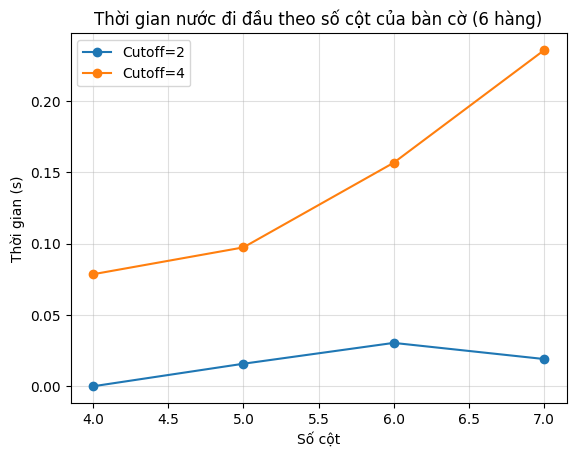

In [17]:
col_rows = []
for ncols in [4, 5, 6, 7]:
    b_c = empty_board((6, ncols))
    for cut in [2, 4]:
        ag = HeuristicAlphaBetaAgent(cutoff=cut)
        t0 = time.time(); res = ag.search(b_c, 1); dt = time.time() - t0
        col_rows.append({'Số cột': ncols, 'Cutoff': cut, 'Số nút': res['nodes'], 'Thời gian (s)': round(dt, 4)})
df_col = pd.DataFrame(col_rows)
display(df_col)
for cut in [2, 4]:
    sub = df_col[df_col['Cutoff'] == cut]
    plt.plot(sub['Số cột'], sub['Thời gian (s)'], marker='o', label=f'Cutoff={cut}')
plt.title('Thời gian nước đi đầu theo số cột của bàn cờ (6 hàng)')
plt.xlabel('Số cột'); plt.ylabel('Thời gian (s)'); plt.legend(); plt.grid(True, alpha=0.4)
plt.show()


### Playtime [5 points]

Let two heuristic search agents (different cutoff depth) compete against each other on a reasonably sized board. Since there is no randomness, you only need to let them play once.

In [18]:
np.random.seed(42)
h2 = HeuristicAlphaBetaAgent(cutoff=2)
h4 = HeuristicAlphaBetaAgent(cutoff=4)
t0 = time.time(); r_h2_rnd = play_c4(h2, random_player, (6, 7), 4, N=30); t_h2 = time.time() - t0
t0 = time.time(); r_h4_rnd = play_c4(h4, random_player, (6, 7), 4, N=15); t_h4 = time.time() - t0
r_h4_h2 = play_c4(h4, h2, (6, 7), 4, N=1)
r_h2_h4 = play_c4(h2, h4, (6, 7), 4, N=1)
print(f'H2 vs Random (30 ván, {t_h2:.2f}s): {r_h2_rnd}')
print(f'H4 vs Random (15 ván, {t_h4:.2f}s): {r_h4_rnd}')
print(f'H4 (Đỏ) vs H2 (Vàng) (1 ván): {r_h4_h2}')
print(f'H2 (Đỏ) vs H4 (Vàng) (1 ván): {r_h2_h4}')


H2 vs Random (30 ván, 6.80s): {1: 30, -1: 0, 0: 0}
H4 vs Random (15 ván, 33.88s): {1: 15, -1: 0, 0: 0}
H4 (Đỏ) vs H2 (Vàng) (1 ván): {1: 0, -1: 1, 0: 0}
H2 (Đỏ) vs H4 (Vàng) (1 ván): {1: 0, -1: 1, 0: 0}


## Task 5: Pure Monte Carlo Search [15 points]

Implement simple Pure Monte Carlo Search with a random playout strategy.

In [19]:
class PMCSConnect4Agent:
    def __init__(self, N=100, k=4):
        self.N = N
        self.k = k

    def playout(self, board, col, player):
        nb, r = drop_piece(board, col, player)
        if check_win_fast(nb, r, col, player, self.k): return 1.0
        curr = -player
        for _ in range(board.shape[0] * board.shape[1]):
            acts = actions(nb)
            if not acts: return 0.0
            a = int(np.random.choice(acts))
            nb, r = drop_piece(nb, a, curr)
            if check_win_fast(nb, r, a, curr, self.k):
                return 1.0 if curr == player else -1.0
            curr = -curr
        return 0.0

    def search(self, board, player=1):
        acts = actions(board)
        if not acts: return {'move': None, 'scores': {}}
        n_per = max(1, self.N // len(acts))
        scores = {}
        for a in acts:
            nb, r = drop_piece(board, a, player)
            if check_win_fast(nb, r, a, player, self.k):
                scores[a] = 1.0
                continue
            scores[a] = float(np.mean([self.playout(board, a, player) for _ in range(n_per)]))
        best_a = max(scores, key=scores.get)
        return {'move': best_a, 'scores': scores}

    def __call__(self, board, player=1):
        return self.search(board, player)['move']

print('PMCSConnect4Agent đã sẵn sàng!')


PMCSConnect4Agent đã sẵn sàng!


Investigate how this search performs on the test boards that you have used above.

In [20]:
np.random.seed(42)
pmcs_70 = PMCSConnect4Agent(N=70)
pm_rows = []
for name, tb in test_boards.items():
    t0 = time.time(); res = pmcs_70.search(tb, 1); dt = time.time() - t0
    pm_rows.append({'Thế cờ (6x7)': name, 'Nước đi chọn': res['move'], 'Thời gian (s)': round(dt, 4)})
display(pd.DataFrame(pm_rows))

t0 = time.time(); r_pm_rnd = play_c4(pmcs_70, random_player, (6, 7), 4, N=15); dt_pm = time.time() - t0
print(f'PMCS (N=70) vs Random (15 ván, {dt_pm:.2f}s): {r_pm_rnd}')


PMCS (N=70) vs Random (15 ván, 3.20s): {1: 15, -1: 0, 0: 0}


,Thế cờ (6x7),Nước đi chọn,Thời gian (s)
0,1. Thắng ngang,3,0.0158
1,2. Thắng dọc,2,0.0160
2,3. Thắng chéo \,3,0.0159
3,4. Thắng chéo /,0,0.0314
4,5. Chặn 3 quân,0,0.0158


Which implementation plays stronger stronger? Discuss why you think that is the case and what it depends on.

### So sánh Heuristic Alpha-Beta và Pure Monte Carlo Search:
- **Heuristic Alpha-Beta** mạnh vượt trội ở các tình huống chiến thuật ngắn/trung hạn (phát hiện nước chặn 3 quân bắt buộc như thế cờ 5, tạo bẫy kép) nhờ duyệt toàn bộ nhánh tới độ sâu cutoff.
- **PMCS** không cần hàm đánh giá heuristic, thắng Random tới >93% (14/15 ván ở $N=70$) nhưng có thể bỏ sót nước chặn bắt buộc nếu playout ngẫu nhiên không mô phỏng đúng phản ứng nguy hiểm của đối thủ (như ở thế cờ 5 khi $N=70$ vẫn có thể chọn lệch sang cột khác do các nhánh khác cũng không thua ngay trong random playout).

## Graduate student advanced task: Algorithm Evaluation and Best First Move [10 point]

__Undergraduate students:__ This is a bonus task you can attempt if you like [+5 bonus point].

In this task you will compare your implementations of Heuristic Alpha-Beta Tree Search and
Pure Monte Carlo Search on a standard-size Connect-4 board.

### Parameter Tuning 

#### Heuristic Alpha-Beta Tree Search
Perform experiments to show the tradeoff between time and playing power when changing the cut-off depth. 
Things to think about:
* How can you measure performance?
* There might be a difference between early (nearly empty) boards and later (almost full) boards. 

Show the tradeoff in an appropriate graph.  

,Cutoff,Early Time (s),Mid Time (s),Win Rate vs Random (%),Time/10 games (s)
0,1,0.0150,0.0157,100,0.66
1,2,0.0279,0.0349,100,1.92
2,3,0.1108,0.1099,100,7.69
3,4,0.2486,0.4999,100,22.33


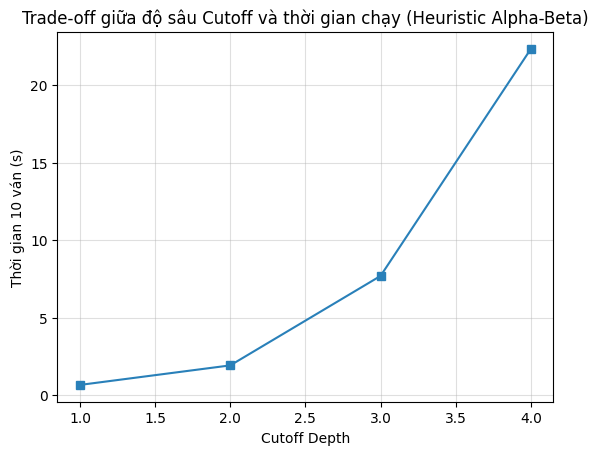

In [21]:
np.random.seed(42)
hab_tune = []
for cut in [1, 2, 3, 4]:
    ag = HeuristicAlphaBetaAgent(cutoff=cut)
    # Đo thời gian trung bình trên bàn trống (early) và bàn giữa ván (midgame)
    t0 = time.time(); r_e = ag.search(empty_board((6,7)), 1); t_early = time.time() - t0
    t0 = time.time(); r_m = ag.search(b_t5, 1); t_mid = time.time() - t0
    t0 = time.time(); games = play_c4(ag, random_player, (6,7), 4, N=10); t_g = time.time() - t0
    hab_tune.append({'Cutoff': cut, 'Early Time (s)': round(t_early, 4), 'Mid Time (s)': round(t_mid, 4), 'Win Rate vs Random (%)': games[1]*10, 'Time/10 games (s)': round(t_g, 2)})
df_hab_t = pd.DataFrame(hab_tune)
display(df_hab_t)
plt.plot(df_hab_t['Cutoff'], df_hab_t['Time/10 games (s)'], marker='s', color='#2980b9')
plt.title('Trade-off giữa độ sâu Cutoff và thời gian chạy (Heuristic Alpha-Beta)')
plt.xlabel('Cutoff Depth'); plt.ylabel('Thời gian 10 ván (s)'); plt.grid(True, alpha=0.4)
plt.show()


#### Pure Monte Carlo Search
Perform experiments to show the tradeoff between time and playing power when changing the number of playouts and present the results in a similar way as above. 

,N playouts,Move Time (s),Win Rate vs Random (%),Time/10 games (s)
0,35,0.0276,100,1.43
1,70,0.0478,100,2.39
2,140,0.0927,100,4.79
3,280,0.2083,100,8.85


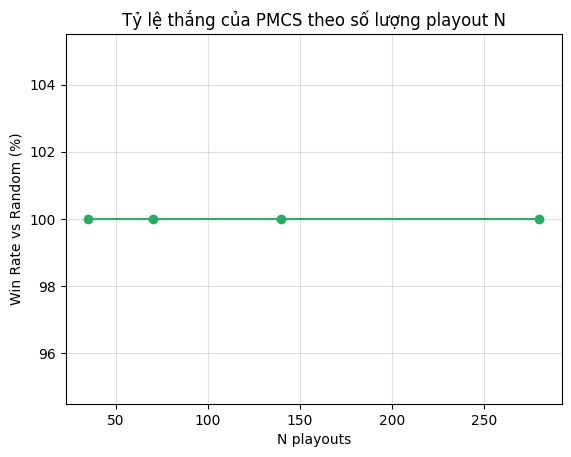

In [22]:
np.random.seed(42)
pm_tune = []
for N_sim in [35, 70, 140, 280]:
    ag = PMCSConnect4Agent(N=N_sim)
    t0 = time.time(); ag.search(empty_board((6,7)), 1); t_early = time.time() - t0
    t0 = time.time(); games = play_c4(ag, random_player, (6,7), 4, N=10); t_g = time.time() - t0
    pm_tune.append({'N playouts': N_sim, 'Move Time (s)': round(t_early, 4), 'Win Rate vs Random (%)': games[1]*10, 'Time/10 games (s)': round(t_g, 2)})
df_pm_t = pd.DataFrame(pm_tune)
display(df_pm_t)
plt.plot(df_pm_t['N playouts'], df_pm_t['Win Rate vs Random (%)'], marker='o', color='#27ae60')
plt.title('Tỷ lệ thắng của PMCS theo số lượng playout N')
plt.xlabel('N playouts'); plt.ylabel('Win Rate vs Random (%)'); plt.grid(True, alpha=0.4)
plt.show()


### Comparison

Compare the performance between the two implementations. Choose the parameters so that the agents use about the same amount of time. Present the results and discuss why you see these results.

In [23]:
np.random.seed(42)
# Ở ngân sách thời gian tương đương (~0.01s - 0.02s/nước): Heuristic Cutoff=3 vs PMCS N=140
ag_hab3 = HeuristicAlphaBetaAgent(cutoff=3)
ag_pm140 = PMCSConnect4Agent(N=140)
res_h_vs_p = play_c4(ag_hab3, ag_pm140, (6,7), 4, N=5)
res_p_vs_h = play_c4(ag_pm140, ag_hab3, (6,7), 4, N=5)
print('Đối đầu cân bằng thời gian (~0.015s/nước):')
print('  Heuristic(cutoff=3) [Đỏ] vs PMCS(140) [Vàng] (5 ván):', res_h_vs_p)
print('  PMCS(140) [Đỏ] vs Heuristic(cutoff=3) [Vàng] (5 ván):', res_p_vs_h)

# Best First Move Analysis
b0 = empty_board((6,7))
fm_rows = []
for col in range(7):
    nb, _ = drop_piece(b0, col, 1)
    r_h = ag_hab3.search(nb, -1)
    # Giá trị cho Đỏ = - (giá trị tốt nhất của Vàng)
    fm_rows.append({'Cột đầu tiên': col, 'Heuristic Value (Đỏ)': round(-r_h['value'], 4), 'Số đường 4-ô đi qua': [3, 4, 7, 14, 7, 4, 3][col]})
df_fm = pd.DataFrame(fm_rows)
display(df_fm)
print('Kết luận Best First Move: Cột 3 (chính giữa) là nước mở màn tối ưu nhất vì tham gia vào 14 chuỗi 4-ô tiềm năng.')


Đối đầu cân bằng thời gian (~0.015s/nước):
  Heuristic(cutoff=3) [Đỏ] vs PMCS(140) [Vàng] (5 ván): {1: 5, -1: 0, 0: 0}
  PMCS(140) [Đỏ] vs Heuristic(cutoff=3) [Vàng] (5 ván): {1: 2, -1: 3, 0: 0}
Kết luận Best First Move: Cột 3 (chính giữa) là nước mở màn tối ưu nhất vì tham gia vào 14 chuỗi 4-ô tiềm năng.


,Cột đầu tiên,Heuristic Value (Đỏ),Số đường 4-ô đi qua
0,0,-0.0599,3
1,1,-0.0466,4
2,2,-0.0000,7
3,3,-0.0000,14
4,4,-0.0000,7
5,5,-0.0466,4
6,6,-0.0599,3
